In [1]:
from Outsu_funs import *

# Import data

## Image downloading

In [2]:
name = "0333"

In [3]:
#!cp /mnt/c/users/helen/Desktop/training_data/{name}.tif ./training_data_Outsu/{name}.tif

Image shape: (512, 512)
Data type: uint16


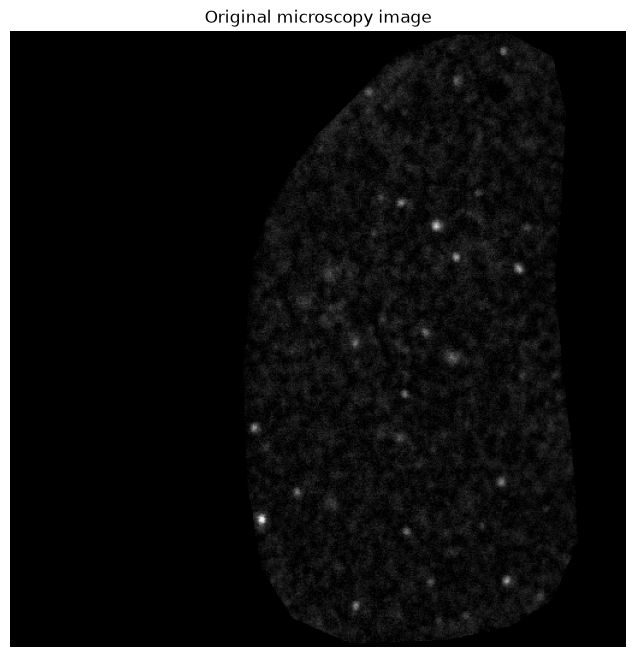

In [4]:
image_path = "training_data_Outsu/"+ name + ".tif"

image = io.imread(image_path)

print("Image shape:", image.shape)
print("Data type:", image.dtype)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")
ax.set_title("Original microscopy image")
ax.axis("off")

plt.show()

# Thresholding

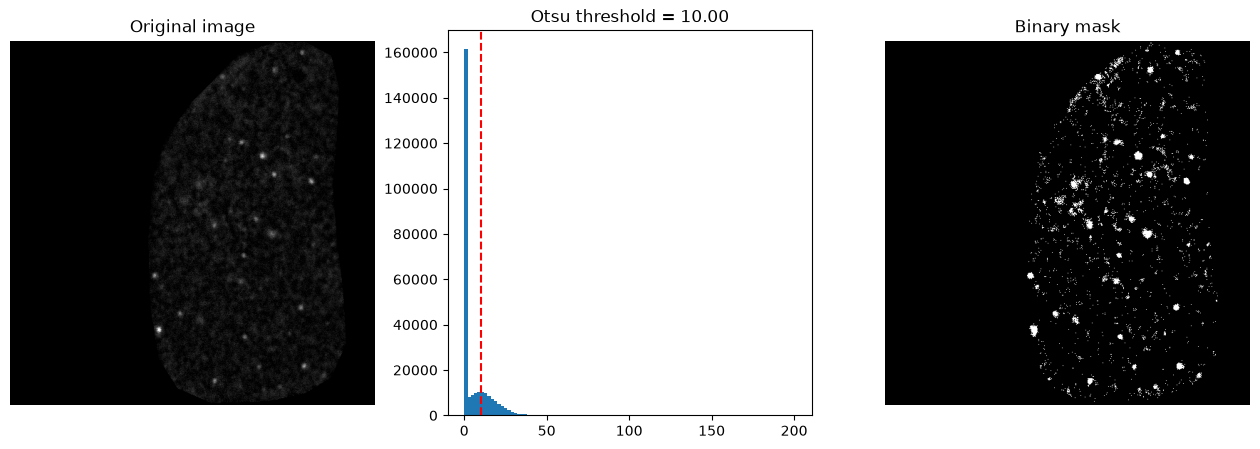

In [5]:
threshold = filters.threshold_otsu(image)
threshold_factor = 3

binary_mask = image > threshold * threshold_factor

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original image")

axes[1].hist(image.ravel(), bins=100)
axes[1].axvline(threshold, color="red", linestyle="--")
axes[1].set_title(f"Otsu threshold = {threshold:.2f}")

axes[2].imshow(binary_mask, cmap="gray")
axes[2].set_title("Binary mask")

for ax in [axes[0], axes[2]]:
    ax.axis("off")

# Cleaning

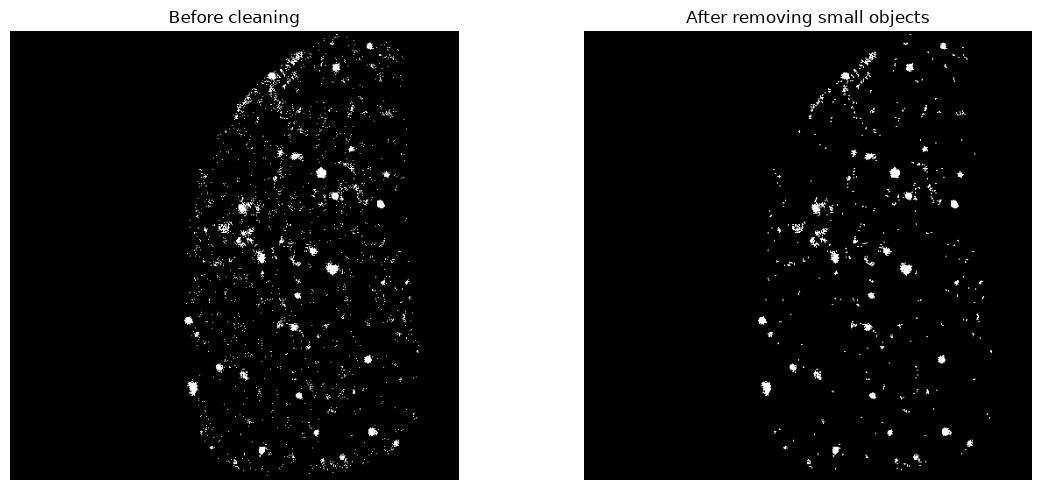

In [6]:
min_area = 2  # pixels

clean_mask = morphology.remove_small_objects(
    binary_mask,
    min_size=min_area
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(binary_mask, cmap="gray")
axes[0].set_title("Before cleaning")

axes[1].imshow(clean_mask, cmap="gray")
axes[1].set_title("After removing small objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Watersheding

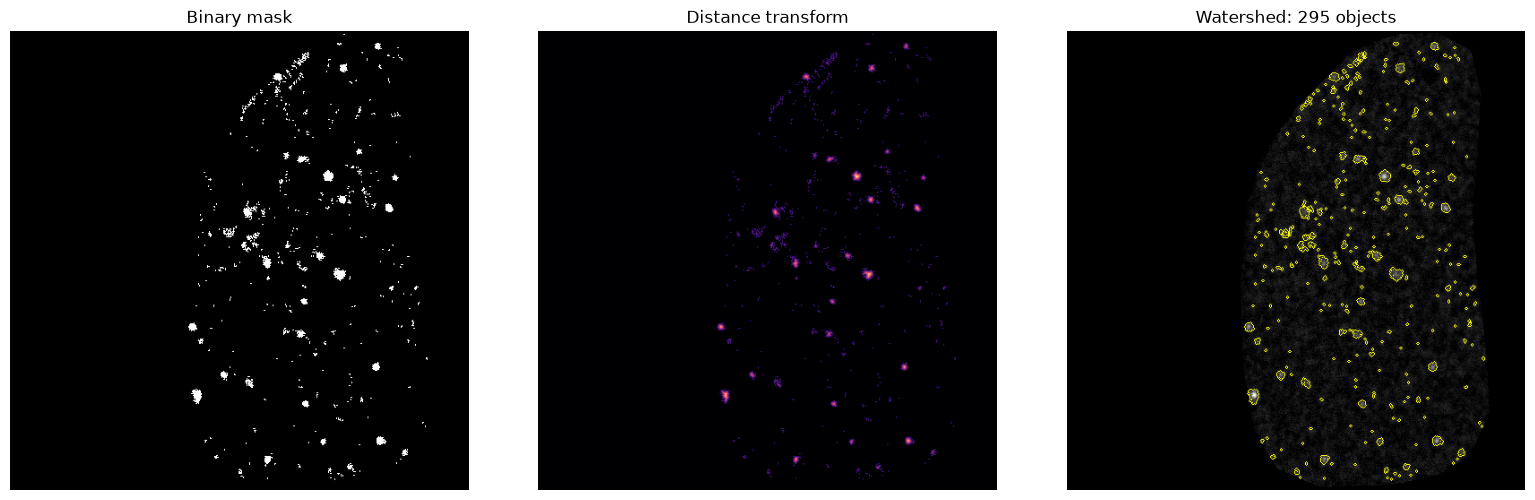

In [7]:
image_float = image.astype(np.float32)

distance = ndi.distance_transform_edt(clean_mask)

# Detect candidate centers
coordinates = peak_local_max(
    distance,
    min_distance=5,
    labels=clean_mask
)

markers = np.zeros_like(clean_mask, dtype=np.int32)

for i, (y, x) in enumerate(coordinates, start=1):
    markers[y, x] = i

labels = segmentation.watershed(
    -distance,
    markers,
    mask=clean_mask
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(clean_mask, cmap="gray")
axes[0].set_title("Binary mask")

axes[1].imshow(distance, cmap="magma")
axes[1].set_title("Distance transform")

axes[2].imshow(
    segmentation.mark_boundaries(
        image_float / (image_float.max() + 1e-8),
        labels
    )
)
axes[2].set_title(f"Watershed: {labels.max()} objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Features analysis

In [8]:
properties = measure.regionprops_table(
    labels,
    intensity_image=image_float,
    properties=[
        "label",
        "area",
        "centroid",
        "equivalent_diameter_area",
        "eccentricity",
        "solidity",
        "perimeter",
        "mean_intensity",
        "max_intensity",
        "min_intensity"
    ]
)

df = pd.DataFrame(properties)

# Circularity: 1 means approximately circular
df["circularity"] = (
    4 * np.pi * df["area"]
    / (df["perimeter"] ** 2 + 1e-8)
)

df["image_id"] = Path(image_path).name

#display(df.head())

print("Total detected objects:", len(df))

Total detected objects: 295


In [9]:
# Save the DataFrame to a CSV file
df.to_csv("training_data_Outsu/"+ name + ".csv", index=False)

### Descriptive statistics of data

In [10]:
#df.describe()

## Feature subset and visualization

In [11]:
#subset = df[(df['area'] > 2)]

#plot_image(
 #   image,
 #   clean_mask,
 #   labels,
 #   df,
 #   mode="image"
#)

In [12]:
#inxs = df[df["area"] > 2.5].index.tolist()

inxs = df.index.tolist()

print("Number of selected objects:", len(inxs))

Number of selected objects: 295


In [59]:
#show_objects_from_list(
 #   image,
  #  labels,
   # df,
    #inxs,
    #padding=30,
    #ncols=3
#)

In [14]:
#!cp ./training_data_Outsu/{name}.csv /mnt/c/users/helen/Desktop/training_data/{name}_labelled.csv

In [15]:
!cp /mnt/c/users/helen/Desktop/training_data/{name}_labelled.csv ./training_data_Outsu/{name}_labelled.csv 

# Combine data

In [55]:
df1 = pd.read_csv("training_data_Outsu/0213_labelled.csv",  sep=";", encoding="cp1252")
df2 = pd.read_csv("training_data_Outsu/0208_labelled.csv",  sep=";", encoding="cp1252")
df3 = pd.read_csv("training_data_Outsu/0241_labelled.csv",  sep=";", encoding="cp1252")
df4 = pd.read_csv("training_data_Outsu/0267_labelled.csv",  sep=";", encoding="cp1252")
df5 = pd.read_csv("training_data_Outsu/0333_labelled.csv",  sep=";", encoding="cp1252")
#df6 = pd.read_csv("training_data_Outsu/0267_labelled.csv",  sep=";", encoding="cp1252")

dfs = [df1, df2, df3, df4, df5]

In [56]:
df_combined = pd.concat(dfs, ignore_index=True)

df = df_combined[
    df_combined["Class"].isin(["foci", "aggregate"])
].reset_index(drop=True)

df.shape

(935, 14)

## Filtration and checking again

In [61]:
df_ready = df_combined[df_combined['area'] > 20]

inxs = df_ready.index.tolist()
print("Number of selected objects:", len(inxs))

Number of selected objects: 137




In [62]:
show_objects_from_list(
    image,
    labels,
    df_ready,
    inxs,
    padding=30,
    ncols=3
)

In [68]:
# Features for classification
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "circularity",
]

# Copy original DataFrame
data = df_ready.copy()

# Clean class labels
data["Class"] = (
    data["Class"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert features to numeric
for feature in features:
    data[feature] = pd.to_numeric(
        data[feature],
        errors="coerce"
    )

# Manually labeled objects
labeled = data[
    data["Class"].isin(["foci", "aggregate"])
].dropna(subset=features).copy()

print("Training samples:")
print(labeled["Class"].value_counts())

Training samples:
Class
aggregate    92
foci         42
Name: count, dtype: Int64


In [69]:
# Model training
X = labeled[features]
y = labeled["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_split=5,
    min_samples_leaf=3,
     max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featu

              precision    recall  f1-score   support

   aggregate       0.90      0.83      0.86        23
        foci       0.69      0.82      0.75        11

    accuracy                           0.82        34
   macro avg       0.80      0.82      0.81        34
weighted avg       0.84      0.82      0.83        34



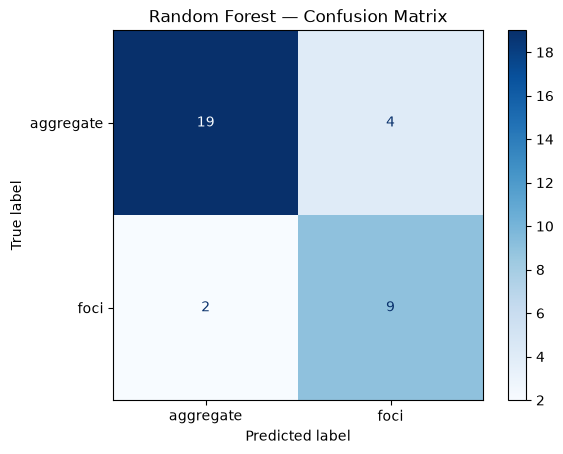

In [70]:
y_pred = rf.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Random Forest — Confusion Matrix")
plt.show()

                    feature  importance       std
3                 perimeter   -0.017866  0.024146
5            mean_intensity   -0.012885  0.029655
2              eccentricity   -0.000909  0.006364
6             max_intensity   -0.000830  0.033331
7               circularity    0.000000  0.000000
1  equivalent_diameter_area    0.019289  0.040211
0                      area    0.023557  0.036178
4                  solidity    0.023636  0.022709


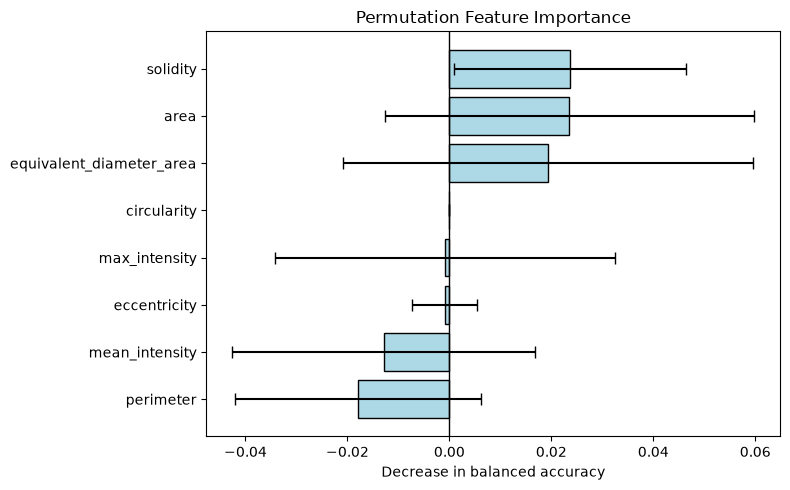

In [71]:
result = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=50,
    random_state=42,
    scoring="balanced_accuracy"
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean,
    "std": result.importances_std
})

importance_df = importance_df.sort_values("importance")

print(importance_df)

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    importance_df["feature"],
    importance_df["importance"],
    xerr=importance_df["std"],
    color="lightblue",
    edgecolor="black",
    capsize=4
)

ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel("Decrease in balanced accuracy")
ax.set_title("Permutation Feature Importance")

plt.tight_layout()
plt.show()

In [72]:
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score
)

for name, X, y in [
    ("Training", X_train, y_train),
    ("Test", X_test, y_test)
]:
    y_pred = rf.predict(X)

    print(f"\n{name}")
    print(
        "Balanced accuracy:",
        balanced_accuracy_score(y, y_pred)
    )
    print(
        "Aggregate F1:",
        f1_score(y, y_pred, pos_label="aggregate")
    )
    
    print(
        "Foci F1:",
        f1_score(y, y_pred, pos_label="foci")
    )



Training
Balanced accuracy: 0.963768115942029
Aggregate F1: 0.9624060150375939
Foci F1: 0.9253731343283582

Test
Balanced accuracy: 0.8221343873517787
Aggregate F1: 0.8636363636363636
Foci F1: 0.75


# Information about features

### Feature distribution

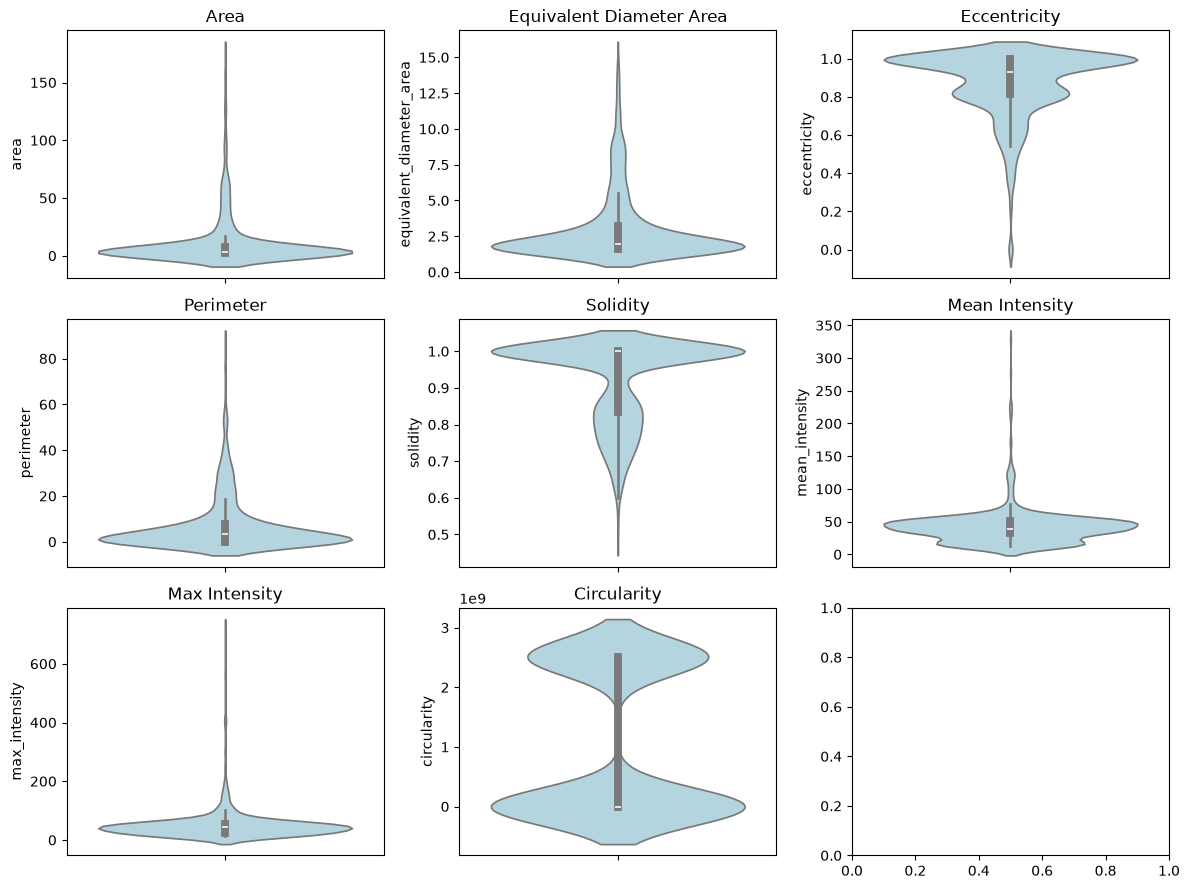

In [74]:
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "circularity",
]

# Clean column names
df_ready = df_ready.copy()
df_ready.columns = df_ready.columns.str.strip().str.lower()

# Convert features to numeric
df_ready[features] = df_ready[features].apply(
    pd.to_numeric,
    errors="coerce"
)

fig, axes = plt.subplots(3, 3, figsize=(12, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


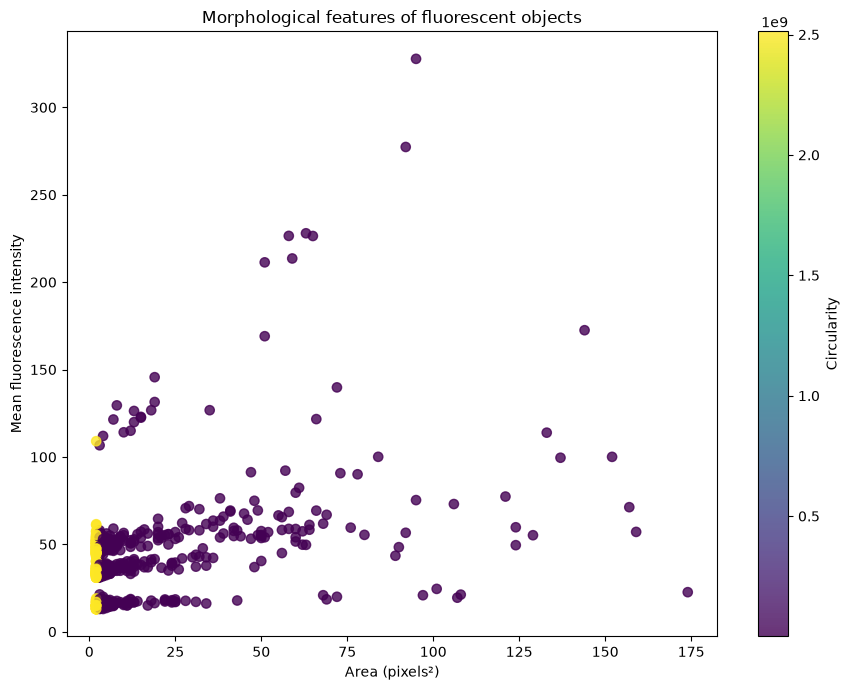

In [75]:
fig, ax = plt.subplots(figsize=(9, 7))

sc = ax.scatter(
    df["area"],
    df["mean_intensity"],
    c=df["circularity"],
    cmap="viridis",
    s=45,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="Circularity")

ax.set_xlabel("Area (pixels²)")
ax.set_ylabel("Mean fluorescence intensity")
ax.set_title("Morphological features of fluorescent objects")

plt.tight_layout()
plt.show()

#  Run PCA

In [76]:
# Features for classification
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "circularity",
]

# Select objects with known classes and complete features
pca_df = df_ready.dropna(subset=features + ["class"]).copy()

# Select features and scale them 
X = pca_df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

### Heatmap of PCA loadings

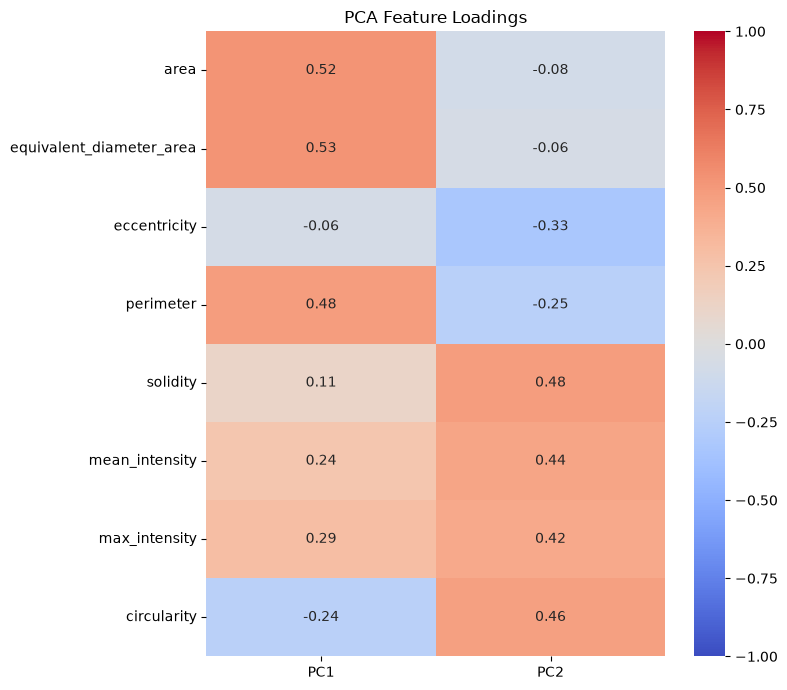

In [77]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [ ]:
# Features for classification
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "circularity",
]

# Select objects with known classes and complete features
pca_df = df_ready.dropna(subset=features + ["class"]).copy()

# Select features and scale them 
X = pca_df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

## Plot PCA

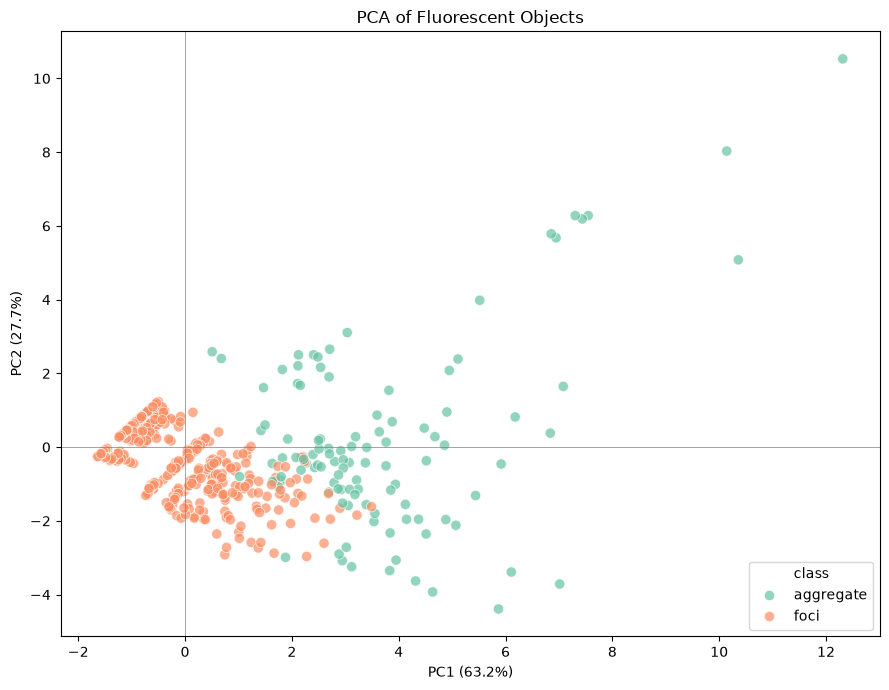

In [30]:
pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="class",
    palette="Set2",
    s=55,
    alpha=0.7
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of Fluorescent Objects")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)

plt.tight_layout()
plt.show()

## Centroids

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Ellipse
from scipy.stats import chi2


def plot_pca_ellipses(
    pca_df,
    group_col="Class",
    pc1="PC1",
    pc2="PC2",
    confidence=0.95,
    show_points=True,
    show_midpoint=True,
    figsize=(9, 7)
):
    fig, ax = plt.subplots(figsize=figsize)

    colors = plt.cm.tab10.colors
    centroids = []

    # Scale for 95% data ellipse
    scale = chi2.ppf(confidence, df=2)

    for i, (group, data) in enumerate(
        pca_df.groupby(group_col)
    ):
        X = data[[pc1, pc2]].dropna().to_numpy(dtype=float)

        n = len(X)
        if n == 0:
            continue

        color = colors[i % len(colors)]

        # Calculate centroid
        centroid = X.mean(axis=0)

        centroids.append({
            group_col: group,
            "PC1_centroid": centroid[0],
            "PC2_centroid": centroid[1],
            "n": n
        })

        # Plot individual observations
        if show_points:
            ax.scatter(
                X[:, 0],
                X[:, 1],
                color=color,
                alpha=0.35,
                s=35,
                label=f"{group} (n={n})"
            )

        # Plot centroid
        ax.scatter(
            centroid[0],
            centroid[1],
            color=color,
            marker="X",
            s=180,
            edgecolor="black",
            linewidth=1,
            zorder=5,
            label=f"{group} centroid"
        )

        # Calculate ellipse
        if n >= 3:
            cov = np.cov(X, rowvar=False)

            eigenvalues, eigenvectors = np.linalg.eigh(cov)

            order = np.argsort(eigenvalues)[::-1]
            eigenvalues = eigenvalues[order]
            eigenvectors = eigenvectors[:, order]

            width, height = (
                2 * np.sqrt(np.maximum(eigenvalues, 0) * scale)
            )

            angle = np.degrees(
                np.arctan2(
                    eigenvectors[1, 0],
                    eigenvectors[0, 0]
                )
            )

            ellipse = Ellipse(
                xy=centroid,
                width=width,
                height=height,
                angle=angle,
                edgecolor=color,
                facecolor=color,
                alpha=0.12
            )

            ax.add_patch(ellipse)

            border = Ellipse(
                xy=centroid,
                width=width,
                height=height,
                angle=angle,
                edgecolor=color,
                facecolor="none",
                linewidth=2
            )

            ax.add_patch(border)

    centroids_df = pd.DataFrame(centroids)

    # Calculate midpoint between the two class centroids
    if show_midpoint and len(centroids_df) == 2:
        midpoint_x = centroids_df["PC1_centroid"].mean()
        midpoint_y = centroids_df["PC2_centroid"].mean()

        ax.scatter(
            midpoint_x,
            midpoint_y,
            color="black",
            marker="D",
            s=100,
            label="Midpoint of centroids",
            zorder=6
        )

        # Connect the two centroids
        ax.plot(
            centroids_df["PC1_centroid"],
            centroids_df["PC2_centroid"],
            color="gray",
            linestyle="--",
            linewidth=1.5,
            alpha=0.7
        )

    ax.axhline(0, color="gray", linestyle="--", alpha=0.3)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.3)

    ax.set_xlabel(pc1, fontsize=12)
    ax.set_ylabel(pc2, fontsize=12)

    ax.set_title(
        f"PCA — {confidence:.0%} Data Ellipses",
        fontsize=14
    )

    ax.legend(frameon=False)
    ax.grid(alpha=0.15)
    ax.set_aspect("equal", adjustable="datalim")

    plt.tight_layout()
    plt.show()

    return centroids_df

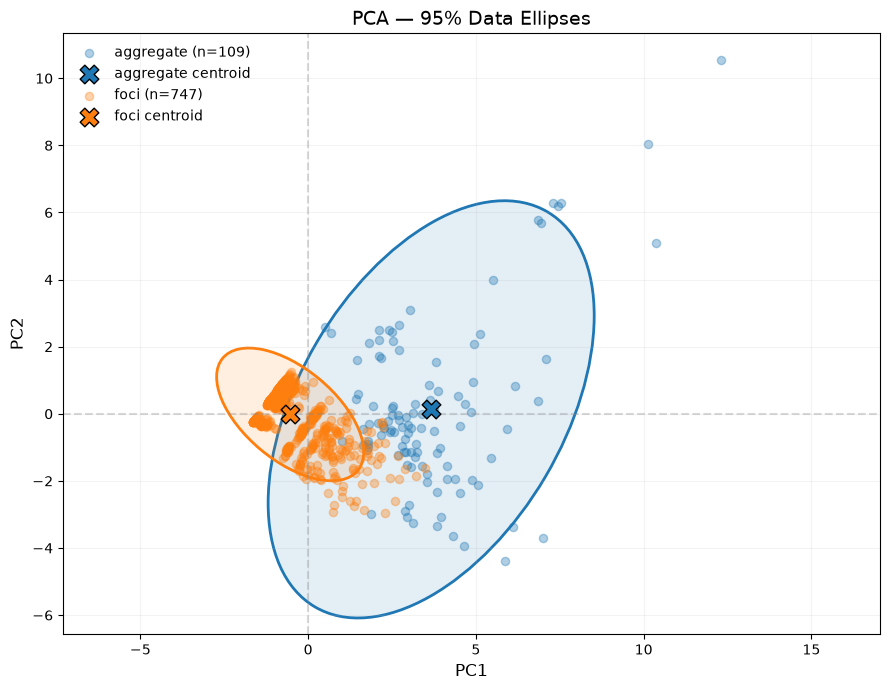

       class  PC1_centroid  PC2_centroid    n
0  aggregate      3.667153      0.131787  109
1       foci     -0.535100     -0.019230  747


In [32]:
centroids = plot_pca_ellipses(
    pca_df,
    group_col="class",
    confidence=0.95,
    show_midpoint=False,
)

print(centroids)

## PERMDISP

In [33]:
from skbio import DistanceMatrix
from skbio.stats.distance import permdisp
from scipy.spatial.distance import pdist, squareform

X = pca_df[["PC1", "PC2"]].to_numpy()
groups = pca_df["class"].to_numpy()

dm = DistanceMatrix(
    squareform(pdist(X, metric="euclidean"))
)

result = permdisp(
    dm,
    grouping=groups,
    permutations=9999
)

print(result)

method name                 PERMDISP
test statistic name          F-value
sample size                      856
number of groups                   2
test statistic            143.521687
p-value                       0.0001
number of permutations          9999
Name: PERMDISP results, dtype: object


## PERMANOVA

In [34]:
from scipy.spatial.distance import pdist, squareform
from skbio import DistanceMatrix
from skbio.stats.distance import permanova, permdisp


def pca_permanova(
    pca_df,
    group_col="Class",
    features=("PC1", "PC2"),
    permutations=9999,
    check_dispersion=True,
    seed=42
):
    # Select data and remove missing values
    df = pca_df[[group_col, *features]].dropna().copy()

    X = df[list(features)].to_numpy(dtype=float)
    groups = df[group_col].to_numpy()

    # Check groups
    if len(np.unique(groups)) < 2:
        raise ValueError("At least two groups are required.")

    # Calculate Euclidean distance matrix
    distances = squareform(
        pdist(X, metric="euclidean")
    )

    dm = DistanceMatrix(
        distances,
        ids=[str(i) for i in range(len(df))]
    )

    # PERMANOVA
    permanova_result = permanova(
        dm,
        grouping=groups,
        permutations=permutations,
        seed=seed
    )

    print("\n===== PERMANOVA =====")
    print(permanova_result)

    # PERMDISP
    permdisp_result = None

    if check_dispersion:
        permdisp_result = permdisp(
            dm,
            grouping=groups,
            permutations=permutations,
            seed=seed
        )

        print("\n===== PERMDISP =====")
        print(permdisp_result)

    return permanova_result, permdisp_result

In [35]:
permanova_result, permdisp_result = pca_permanova(
    pca_df,
    group_col="class",
    features=("PC1", "PC2"),
    permutations=9999
)


===== PERMANOVA =====
method name                PERMANOVA
test statistic name         pseudo-F
sample size                      856
number of groups                   2
test statistic            650.353267
p-value                       0.0001
number of permutations          9999
Name: PERMANOVA results, dtype: object

===== PERMDISP =====
method name                 PERMDISP
test statistic name          F-value
sample size                      856
number of groups                   2
test statistic            143.521687
p-value                       0.0001
number of permutations          9999
Name: PERMDISP results, dtype: object


## BOOTSTRAP

In [36]:
def compare_pca_centroids(
    pca_df,
    group_col="Class",
    features=("PC1", "PC2"),
    n_boot=10000,
    confidence=0.95,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    df = pca_df[[group_col, *features]].dropna()

    groups = list(df[group_col].unique())

    if len(groups) != 2:
        raise ValueError("Exactly two groups are required.")

    X1 = df.loc[
        df[group_col] == groups[0], list(features)
    ].to_numpy(dtype=float)

    X2 = df.loc[
        df[group_col] == groups[1], list(features)
    ].to_numpy(dtype=float)

    # Observed centroids
    c1 = X1.mean(axis=0)
    c2 = X2.mean(axis=0)

    # Observed difference
    difference = c1 - c2
    distance = np.linalg.norm(difference)

    # Bootstrap
    boot_diff = np.zeros((n_boot, len(features)))
    boot_distance = np.zeros(n_boot)

    for i in range(n_boot):
        s1 = X1[
            rng.integers(0, len(X1), len(X1))
        ]

        s2 = X2[
            rng.integers(0, len(X2), len(X2))
        ]

        diff = s1.mean(axis=0) - s2.mean(axis=0)

        boot_diff[i] = diff
        boot_distance[i] = np.linalg.norm(diff)

    alpha = 1 - confidence

    # Confidence intervals for each coordinate difference
    ci_diff = np.quantile(
        boot_diff,
        [alpha / 2, 1 - alpha / 2],
        axis=0
    )

    # Confidence interval for distance
    ci_distance = np.quantile(
        boot_distance,
        [alpha / 2, 1 - alpha / 2]
    )

    print(f"Groups: {groups[0]} vs {groups[1]}")
    print(f"Centroid 1: {c1}")
    print(f"Centroid 2: {c2}")

    print(f"\nCentroid distance: {distance:.4f}")
    print(
        f"{confidence:.0%} bootstrap CI for distance: "
        f"[{ci_distance[0]:.4f}, {ci_distance[1]:.4f}]"
    )

    for j, feature in enumerate(features):
        print(
            f"{feature} difference: {difference[j]:.4f}, "
            f"CI [{ci_diff[0, j]:.4f}, "
            f"{ci_diff[1, j]:.4f}]"
        )

    return {
        "groups": groups,
        "centroids": (c1, c2),
        "difference": difference,
        "distance": distance,
        "distance_CI": ci_distance,
        "coordinate_CI": ci_diff,
        "bootstrap_distances": boot_distance
    }

In [37]:
results = compare_pca_centroids(
    pca_df,
    group_col="class",
    features=("PC1", "PC2"),
    n_boot=10000
)

Groups: aggregate vs foci
Centroid 1: [3.66715251 0.13178673]
Centroid 2: [-0.5350999  -0.01922992]

Centroid distance: 4.2050
95% bootstrap CI for distance: [3.8429, 4.6198]
PC1 difference: 4.2023, CI [3.8363, 4.5971]
PC2 difference: 0.1510, CI [-0.3161, 0.6401]


### Correlation analysis

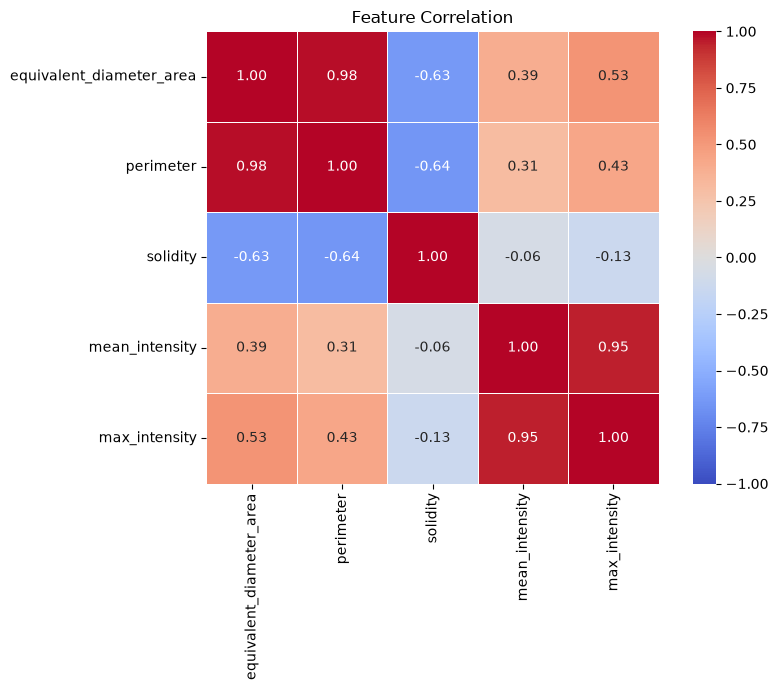

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 7))

sns.heatmap(
    X_train.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Feature Correlation")
plt.tight_layout()
plt.show()